In [1]:
import sys
import pandas as pd

print("Python location:", sys.executable)
print("Pandas version:", pd.__version__)
print("Marketplace Intelligence is ready!")

Python location: c:\DataAnalytics\Marketplace-Intelligence\.venv\Scripts\python.exe
Pandas version: 3.1.1
Marketplace Intelligence is ready!


In [2]:
from pathlib import Path

# Locate the main project folder
project_folder = Path.cwd()

if project_folder.name == "notebooks":
    project_folder = project_folder.parent

# Find the orders dataset
file_path = project_folder / "data" / "raw" / "olist_orders_dataset.csv"

print("Dataset location:", file_path)
print("File exists:", file_path.exists())

Dataset location: c:\DataAnalytics\Marketplace-Intelligence\data\raw\olist_orders_dataset.csv
File exists: True


In [3]:
# Read the CSV dataset
orders = pd.read_csv(file_path)

print("Orders dataset loaded successfully!")

# Display the first 5 rows
orders.head()

Orders dataset loaded successfully!


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [4]:
# Find the number of rows and columns

print("Dataset dimensions:", orders.shape)

print("Total number of orders:", orders.shape[0])

print("Total number of columns:", orders.shape[1])

Dataset dimensions: (99441, 8)
Total number of orders: 99441
Total number of columns: 8


In [5]:
# Display all column names

print("Column names:")

for column in orders.columns:
    print(column)

Column names:
order_id
customer_id
order_status
order_purchase_timestamp
order_approved_at
order_delivered_carrier_date
order_delivered_customer_date
order_estimated_delivery_date


In [6]:
# Display dataset information

orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB


In [7]:
# Count missing values in each column

missing_values = orders.isnull().sum()

print("Missing values in each column:")
print(missing_values)


Missing values in each column:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


In [8]:
# Calculate missing value percentages

missing_percentage = (
    orders.isnull().mean() * 100
).round(2)

print(missing_percentage)

order_id                         0.00
customer_id                      0.00
order_status                     0.00
order_purchase_timestamp         0.00
order_approved_at                0.16
order_delivered_carrier_date     1.79
order_delivered_customer_date    2.98
order_estimated_delivery_date    0.00
dtype: float64


In [9]:
# Check duplicate rows

duplicate_count = orders.duplicated().sum()

print("Total duplicate rows:", duplicate_count)

Total duplicate rows: 0


In [10]:
# Create a missing-value summary

missing_report = pd.DataFrame({
    "Missing_Count": orders.isnull().sum(),
    "Missing_Percentage": (
        orders.isnull().mean() * 100
    ).round(2)
})

missing_report = missing_report.sort_values(
    by="Missing_Count",
    ascending=False
)

missing_report

,Missing_Count,Missing_Percentage
order_delivered_customer_date,2965,2.98
order_delivered_carrier_date,1783,1.79
order_approved_at,160,0.16
order_id,0,0.00
order_purchase_timestamp,0,0.00
order_status,0,0.00
customer_id,0,0.00
order_estimated_delivery_date,0,0.00


In [11]:
# Count orders by status

orders["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [12]:
# Investigate missing delivery dates by order status

delivery_missing_analysis = orders.groupby(
    "order_status"
).agg(
    Total_Orders=("order_id", "count"),
    Missing_Delivery_Dates=(
        "order_delivered_customer_date",
        lambda x: x.isnull().sum()
    )
)

delivery_missing_analysis["Missing_Percentage"] = (
    delivery_missing_analysis["Missing_Delivery_Dates"]
    / delivery_missing_analysis["Total_Orders"] * 100
).round(2)

delivery_missing_analysis

,Total_Orders,Missing_Delivery_Dates,Missing_Percentage
order_status,,,
approved,2,2,100.00
canceled,625,619,99.04
created,5,5,100.00
delivered,96478,8,0.01
invoiced,314,314,100.00
processing,301,301,100.00
shipped,1107,1107,100.00
unavailable,609,609,100.00


In [13]:
# Check unique order IDs

print("Total order records:", len(orders))

print("Unique order IDs:", orders["order_id"].nunique())

print(
    "Duplicate order IDs:",
    orders["order_id"].duplicated().sum()
)

Total order records: 99441
Unique order IDs: 99441
Duplicate order IDs: 0


In [14]:
# Find delivered orders with missing delivery dates

delivered_missing = orders[
    (orders["order_status"] == "delivered") &
    (orders["order_delivered_customer_date"].isnull())
]

print("Number of unusual orders:", len(delivered_missing))

delivered_missing

Number of unusual orders: 8


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,ec05a6d8558c6455f0cbbd8a420ad34f,delivered,2017-11-28 17:44:07,2017-11-28 17:56:40,2017-11-30 18:12:23,NaN,2017-12-18 00:00:00
20618,f5dd62b788049ad9fc0526e3ad11a097,5e89028e024b381dc84a13a3570decb4,delivered,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaN,2018-07-16 00:00:00
43834,2ebdfc4f15f23b91474edf87475f108e,29f0540231702fda0cfdee0a310f11aa,delivered,2018-07-01 17:05:11,2018-07-01 17:15:12,2018-07-03 13:57:00,NaN,2018-07-30 00:00:00
79263,e69f75a717d64fc5ecdfae42b2e8e086,cfda40ca8dd0a5d486a9635b611b398a,delivered,2018-07-01 22:05:55,2018-07-01 22:15:14,2018-07-03 13:57:00,NaN,2018-07-30 00:00:00
82868,0d3268bad9b086af767785e3f0fc0133,4f1d63d35fb7c8999853b2699f5c7649,delivered,2018-07-01 21:14:02,2018-07-01 21:29:54,2018-07-03 09:28:00,NaN,2018-07-24 00:00:00
92643,2d858f451373b04fb5c984a1cc2defaf,e08caf668d499a6d643dafd7c5cc498a,delivered,2017-05-25 23:22:43,2017-05-25 23:30:16,NaN,NaN,2017-06-23 00:00:00
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,dd1b84a7286eb4524d52af4256c0ba24,delivered,2018-06-08 12:09:39,2018-06-08 12:36:39,2018-06-12 14:10:00,NaN,2018-06-26 00:00:00
98038,20edc82cf5400ce95e1afacc25798b31,28c37425f1127d887d7337f284080a0f,delivered,2018-06-27 16:09:12,2018-06-27 16:29:30,2018-07-03 19:26:00,NaN,2018-07-19 00:00:00


In [15]:
# Display important information about these orders

delivered_missing[
    [
        "order_id",
        "order_status",
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
]

,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,delivered,2017-11-28 17:44:07,2017-11-28 17:56:40,2017-11-30 18:12:23,NaN,2017-12-18 00:00:00
20618,f5dd62b788049ad9fc0526e3ad11a097,delivered,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaN,2018-07-16 00:00:00
43834,2ebdfc4f15f23b91474edf87475f108e,delivered,2018-07-01 17:05:11,2018-07-01 17:15:12,2018-07-03 13:57:00,NaN,2018-07-30 00:00:00
79263,e69f75a717d64fc5ecdfae42b2e8e086,delivered,2018-07-01 22:05:55,2018-07-01 22:15:14,2018-07-03 13:57:00,NaN,2018-07-30 00:00:00
82868,0d3268bad9b086af767785e3f0fc0133,delivered,2018-07-01 21:14:02,2018-07-01 21:29:54,2018-07-03 09:28:00,NaN,2018-07-24 00:00:00
92643,2d858f451373b04fb5c984a1cc2defaf,delivered,2017-05-25 23:22:43,2017-05-25 23:30:16,NaN,NaN,2017-06-23 00:00:00
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,delivered,2018-06-08 12:09:39,2018-06-08 12:36:39,2018-06-12 14:10:00,NaN,2018-06-26 00:00:00
98038,20edc82cf5400ce95e1afacc25798b31,delivered,2018-06-27 16:09:12,2018-06-27 16:29:30,2018-07-03 19:26:00,NaN,2018-07-19 00:00:00


In [16]:
# Find cancelled orders with delivery dates

cancelled_with_delivery = orders[
    (orders["order_status"] == "canceled") &
    (orders["order_delivered_customer_date"].notnull())
]

print(
    "Cancelled orders with delivery dates:",
    len(cancelled_with_delivery)
)

cancelled_with_delivery

Cancelled orders with delivery dates: 6


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
2921,1950d777989f6a877539f53795b4c3c3,1bccb206de9f0f25adc6871a1bcf77b2,canceled,2018-02-19 19:48:52,2018-02-19 20:56:05,2018-02-20 19:57:13,2018-03-21 22:03:51,2018-03-09 00:00:00
8791,dabf2b0e35b423f94618bf965fcb7514,5cdec0bb8cbdf53ffc8fdc212cd247c6,canceled,2016-10-09 00:56:52,2016-10-09 13:36:58,2016-10-13 13:36:59,2016-10-16 14:36:59,2016-11-30 00:00:00
58266,770d331c84e5b214bd9dc70a10b829d0,6c57e6119369185e575b36712766b0ef,canceled,2016-10-07 14:52:30,2016-10-07 15:07:10,2016-10-11 15:07:11,2016-10-14 15:07:11,2016-11-29 00:00:00
59332,8beb59392e21af5eb9547ae1a9938d06,bf609b5741f71697f65ce3852c5d2623,canceled,2016-10-08 20:17:50,2016-10-09 14:34:30,2016-10-14 22:45:26,2016-10-19 18:47:43,2016-11-30 00:00:00
92636,65d1e226dfaeb8cdc42f665422522d14,70fc57eeae292675927697fe03ad3ff5,canceled,2016-10-03 21:01:41,2016-10-04 10:18:57,2016-10-25 12:14:28,2016-11-08 10:58:34,2016-11-25 00:00:00
94399,2c45c33d2f9cb8ff8b1c86cc28c11c30,de4caa97afa80c8eeac2ff4c8da5b72e,canceled,2016-10-09 15:39:56,2016-10-10 10:40:49,2016-10-14 10:40:50,2016-11-09 14:53:50,2016-12-08 00:00:00


In [17]:
# Examine the six cancelled orders

cancelled_with_delivery[
    [
        "order_id",
        "order_status",
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
]

,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
2921,1950d777989f6a877539f53795b4c3c3,canceled,2018-02-19 19:48:52,2018-02-19 20:56:05,2018-02-20 19:57:13,2018-03-21 22:03:51,2018-03-09 00:00:00
8791,dabf2b0e35b423f94618bf965fcb7514,canceled,2016-10-09 00:56:52,2016-10-09 13:36:58,2016-10-13 13:36:59,2016-10-16 14:36:59,2016-11-30 00:00:00
58266,770d331c84e5b214bd9dc70a10b829d0,canceled,2016-10-07 14:52:30,2016-10-07 15:07:10,2016-10-11 15:07:11,2016-10-14 15:07:11,2016-11-29 00:00:00
59332,8beb59392e21af5eb9547ae1a9938d06,canceled,2016-10-08 20:17:50,2016-10-09 14:34:30,2016-10-14 22:45:26,2016-10-19 18:47:43,2016-11-30 00:00:00
92636,65d1e226dfaeb8cdc42f665422522d14,canceled,2016-10-03 21:01:41,2016-10-04 10:18:57,2016-10-25 12:14:28,2016-11-08 10:58:34,2016-11-25 00:00:00
94399,2c45c33d2f9cb8ff8b1c86cc28c11c30,canceled,2016-10-09 15:39:56,2016-10-10 10:40:49,2016-10-14 10:40:50,2016-11-09 14:53:50,2016-12-08 00:00:00


In [18]:
# Examine the eight delivered orders with missing delivery dates

delivered_missing[
    [
        "order_id",
        "order_status",
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
]

,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,delivered,2017-11-28 17:44:07,2017-11-28 17:56:40,2017-11-30 18:12:23,NaN,2017-12-18 00:00:00
20618,f5dd62b788049ad9fc0526e3ad11a097,delivered,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaN,2018-07-16 00:00:00
43834,2ebdfc4f15f23b91474edf87475f108e,delivered,2018-07-01 17:05:11,2018-07-01 17:15:12,2018-07-03 13:57:00,NaN,2018-07-30 00:00:00
79263,e69f75a717d64fc5ecdfae42b2e8e086,delivered,2018-07-01 22:05:55,2018-07-01 22:15:14,2018-07-03 13:57:00,NaN,2018-07-30 00:00:00
82868,0d3268bad9b086af767785e3f0fc0133,delivered,2018-07-01 21:14:02,2018-07-01 21:29:54,2018-07-03 09:28:00,NaN,2018-07-24 00:00:00
92643,2d858f451373b04fb5c984a1cc2defaf,delivered,2017-05-25 23:22:43,2017-05-25 23:30:16,NaN,NaN,2017-06-23 00:00:00
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,delivered,2018-06-08 12:09:39,2018-06-08 12:36:39,2018-06-12 14:10:00,NaN,2018-06-26 00:00:00
98038,20edc82cf5400ce95e1afacc25798b31,delivered,2018-06-27 16:09:12,2018-06-27 16:29:30,2018-07-03 19:26:00,NaN,2018-07-19 00:00:00


In [19]:
# Compare available delivery dates

cancelled_with_delivery[
    [
        "order_id",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
].sort_values("order_delivered_customer_date")

,order_id,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
58266,770d331c84e5b214bd9dc70a10b829d0,2016-10-11 15:07:11,2016-10-14 15:07:11,2016-11-29 00:00:00
8791,dabf2b0e35b423f94618bf965fcb7514,2016-10-13 13:36:59,2016-10-16 14:36:59,2016-11-30 00:00:00
59332,8beb59392e21af5eb9547ae1a9938d06,2016-10-14 22:45:26,2016-10-19 18:47:43,2016-11-30 00:00:00
92636,65d1e226dfaeb8cdc42f665422522d14,2016-10-25 12:14:28,2016-11-08 10:58:34,2016-11-25 00:00:00
94399,2c45c33d2f9cb8ff8b1c86cc28c11c30,2016-10-14 10:40:50,2016-11-09 14:53:50,2016-12-08 00:00:00
2921,1950d777989f6a877539f53795b4c3c3,2018-02-20 19:57:13,2018-03-21 22:03:51,2018-03-09 00:00:00


In [20]:
# Check the data types of all columns

orders.dtypes

order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object

In [21]:
# Create a copy of the original orders dataset

orders_clean = orders.copy()

print("Cleaned dataset copy created!")

Cleaned dataset copy created!


In [22]:
# Identify all date columns

date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

print("Date columns selected:")
print(date_columns)

Date columns selected:
['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']


In [23]:
# Convert all date columns into datetime format

for column in date_columns:

    orders_clean[column] = pd.to_datetime(
        orders_clean[column],
        errors="coerce"
    )

print("All date columns converted successfully!")

All date columns converted successfully!


In [24]:
# Check the converted date columns

orders_clean[date_columns].dtypes

order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

In [25]:
# Compare missing dates before and after conversion

before_missing = orders[date_columns].isnull().sum()

after_missing = orders_clean[date_columns].isnull().sum()

conversion_report = pd.DataFrame({
    "Before_Conversion": before_missing,
    "After_Conversion": after_missing
})

conversion_report["New_Missing_Values"] = (
    conversion_report["After_Conversion"]
    - conversion_report["Before_Conversion"]
)

conversion_report

,Before_Conversion,After_Conversion,New_Missing_Values
order_purchase_timestamp,0,0,0
order_approved_at,160,160,0
order_delivered_carrier_date,1783,1783,0
order_delivered_customer_date,2965,2965,0
order_estimated_delivery_date,0,0,0


In [26]:
# Display the first 10 converted dates

orders_clean[
    [
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
].head(10)

,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date
0,2017-10-02 10:56:33,2017-10-10 21:25:13,2017-10-18
1,2018-07-24 20:41:37,2018-08-07 15:27:45,2018-08-13
2,2018-08-08 08:38:49,2018-08-17 18:06:29,2018-09-04
3,2017-11-18 19:28:06,2017-12-02 00:28:42,2017-12-15
4,2018-02-13 21:18:39,2018-02-16 18:17:02,2018-02-26
5,2017-07-09 21:57:05,2017-07-26 10:57:55,2017-08-01
6,2017-04-11 12:22:08,NaT,2017-05-09
7,2017-05-16 13:10:30,2017-05-26 12:55:51,2017-06-07
8,2017-01-23 18:29:09,2017-02-02 14:08:10,2017-03-06
9,2017-07-29 11:55:02,2017-08-16 17:14:30,2017-08-23


In [27]:
# Select delivered orders

delivered_orders = orders_clean[
    orders_clean["order_status"] == "delivered"
].copy()

print("Total delivered orders:", len(delivered_orders))

Total delivered orders: 96478


In [28]:
# Remove incomplete records only from this analysis

valid_deliveries = delivered_orders.dropna(
    subset=[
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
).copy()

print("Orders available for delivery analysis:", len(valid_deliveries))

Orders available for delivery analysis: 96470


In [29]:
# Calculate delivery duration in days

valid_deliveries["delivery_days"] = (
    valid_deliveries["order_delivered_customer_date"]
    - valid_deliveries["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Check negative delivery durations

negative_deliveries = (
    valid_deliveries["delivery_days"] < 0
).sum()

print("Negative delivery durations:", negative_deliveries)

Negative delivery durations: 0


In [30]:
# Keep records with non-negative delivery duration

analysis_deliveries = valid_deliveries[
    valid_deliveries["delivery_days"] >= 0
].copy()

average_delivery = analysis_deliveries["delivery_days"].mean()

median_delivery = analysis_deliveries["delivery_days"].median()

print("Average delivery time:", round(average_delivery, 2), "days")

print("Median delivery time:", round(median_delivery, 2), "days")

Average delivery time: 12.56 days
Median delivery time: 10.22 days


In [31]:
# Identify late deliveries

analysis_deliveries["is_late"] = (
    analysis_deliveries["order_delivered_customer_date"]
    > analysis_deliveries["order_estimated_delivery_date"]
)

late_orders = analysis_deliveries["is_late"].sum()

total_analysed_orders = len(analysis_deliveries)

late_percentage = (
    late_orders / total_analysed_orders
) * 100

on_time_percentage = 100 - late_percentage

print("Total analysed orders:", total_analysed_orders)

print("Late orders:", late_orders)

print("Late delivery percentage:", round(late_percentage, 2), "%")

print("On-time delivery percentage:", round(on_time_percentage, 2), "%")

Total analysed orders: 96470
Late orders: 7826
Late delivery percentage: 8.11 %
On-time delivery percentage: 91.89 %


In [32]:
import matplotlib.pyplot as plt

In [33]:
# Calculate delivery performance summary

delivery_summary = pd.DataFrame({
    "Delivery_Status": ["On Time", "Late"],
    "Number_of_Orders": [
        (analysis_deliveries["is_late"] == False).sum(),
        analysis_deliveries["is_late"].sum()
    ]
})

delivery_summary

,Delivery_Status,Number_of_Orders
0,On Time,88644
1,Late,7826


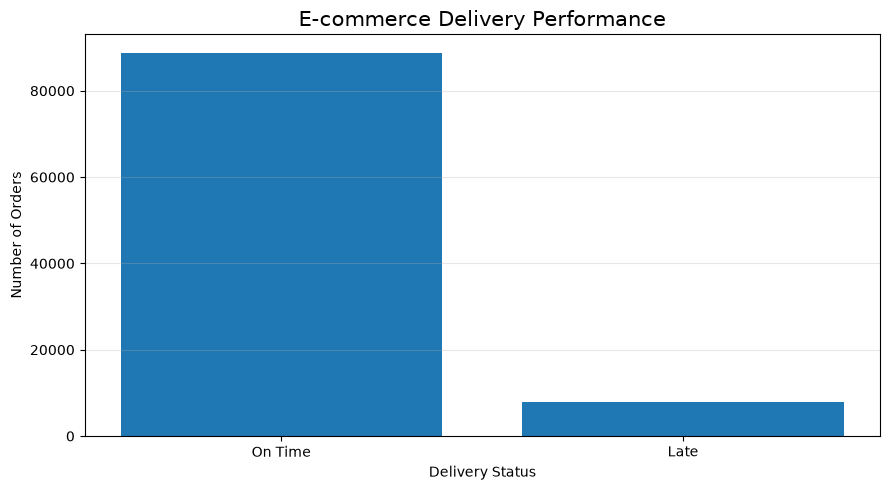

In [34]:
# Create delivery performance chart

plt.figure(figsize=(9, 5))

plt.bar(
    delivery_summary["Delivery_Status"],
    delivery_summary["Number_of_Orders"]
)

plt.title("E-commerce Delivery Performance", fontsize=15)

plt.xlabel("Delivery Status")

plt.ylabel("Number of Orders")

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.show()

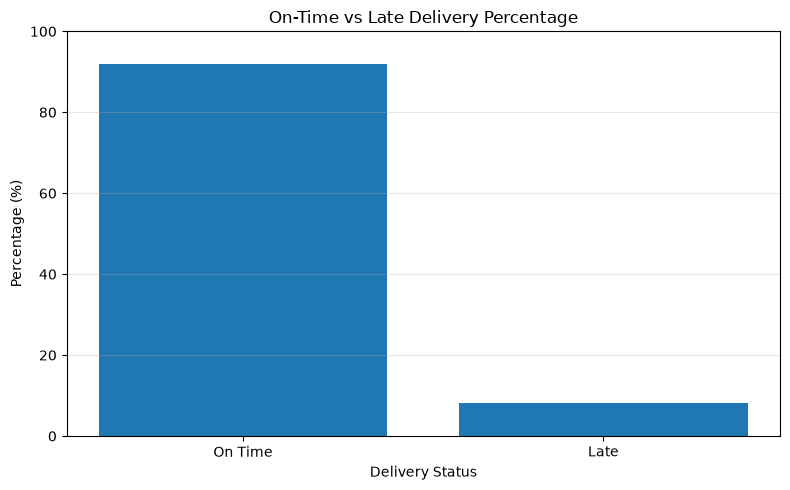

In [35]:
# Calculate percentages for visualization

delivery_percentages = [
    on_time_percentage,
    late_percentage
]

plt.figure(figsize=(8, 5))

plt.bar(
    ["On Time", "Late"],
    delivery_percentages
)

plt.title("On-Time vs Late Delivery Percentage")

plt.xlabel("Delivery Status")

plt.ylabel("Percentage (%)")

plt.ylim(0, 100)

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.show()


In [36]:
# Create a copy for monthly analysis

monthly_data = analysis_deliveries.copy()

# Extract purchase month

monthly_data["purchase_month"] = (
    monthly_data["order_purchase_timestamp"]
    .dt.to_period("M")
)

print("Monthly analysis dataset created!")

monthly_data[
    ["order_id", "purchase_month", "delivery_days", "is_late"]
].head()

Monthly analysis dataset created!


,order_id,purchase_month,delivery_days,is_late
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10,8.436574,False
1,53cdb2fc8bc7dce0b6741e2150273451,2018-07,13.782037,False
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08,9.394213,False
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-11,13.208750,False
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02,2.873877,False


In [37]:
# Calculate monthly delivery performance

monthly_performance = monthly_data.groupby(
    "purchase_month"
).agg(
    total_orders=("order_id", "count"),
    late_orders=("is_late", "sum"),
    average_delivery_days=("delivery_days", "mean")
)

# Calculate monthly late delivery percentage

monthly_performance["late_percentage"] = (
    monthly_performance["late_orders"]
    / monthly_performance["total_orders"] * 100
).round(2)

monthly_performance["average_delivery_days"] = (
    monthly_performance["average_delivery_days"].round(2)
)

monthly_performance

,total_orders,late_orders,average_delivery_days,late_percentage
purchase_month,,,,
2016-09,1,1,54.81,100.00
2016-10,265,3,19.60,1.13
2016-12,1,0,4.69,0.00
2017-01,750,23,12.65,3.07
2017-02,1653,53,13.17,3.21
2017-03,2546,142,12.95,5.58
2017-04,2303,181,14.92,7.86
2017-05,3545,128,11.32,3.61
2017-06,3135,121,12.01,3.86


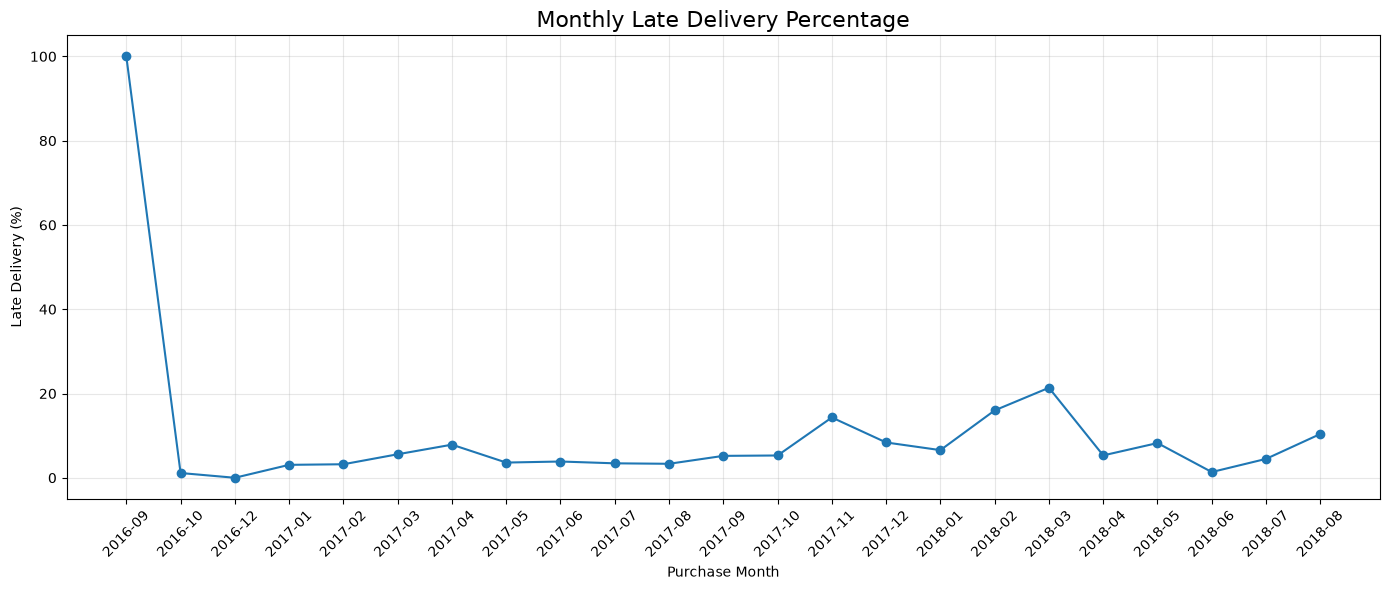

In [38]:
# Visualize monthly late delivery percentage

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_performance.index.astype(str),
    monthly_performance["late_percentage"],
    marker="o"
)

plt.title(
    "Monthly Late Delivery Percentage",
    fontsize=16
)

plt.xlabel("Purchase Month")
plt.ylabel("Late Delivery (%)")

plt.xticks(rotation=45)

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

In [39]:
# Find the month with the highest and lowest late percentage

worst_month = monthly_performance["late_percentage"].idxmax()

best_month = monthly_performance["late_percentage"].idxmin()

print("Worst delivery performance month:", worst_month)

print(
    "Highest late delivery percentage:",
    monthly_performance.loc[worst_month, "late_percentage"],
    "%"
)

print("\nBest delivery performance month:", best_month)

print(
    "Lowest late delivery percentage:",
    monthly_performance.loc[best_month, "late_percentage"],
    "%"
)

Worst delivery performance month: 2016-09
Highest late delivery percentage: 100.0 %

Best delivery performance month: 2016-12
Lowest late delivery percentage: 0.0 %


In [40]:
# Check the number of orders in each month

monthly_performance[
    ["total_orders", "late_orders", "late_percentage"]
]

,total_orders,late_orders,late_percentage
purchase_month,,,
2016-09,1,1,100.00
2016-10,265,3,1.13
2016-12,1,0,0.00
2017-01,750,23,3.07
2017-02,1653,53,3.21
2017-03,2546,142,5.58
2017-04,2303,181,7.86
2017-05,3545,128,3.61
2017-06,3135,121,3.86


In [41]:
# Analyse complete months only

complete_monthly_performance = monthly_performance.loc[
    "2017-01":"2018-08"
].copy()

print("Number of complete months:", len(complete_monthly_performance))

complete_monthly_performance

Number of complete months: 20


,total_orders,late_orders,average_delivery_days,late_percentage
purchase_month,,,,
2017-01,750,23,12.65,3.07
2017-02,1653,53,13.17,3.21
2017-03,2546,142,12.95,5.58
2017-04,2303,181,14.92,7.86
2017-05,3545,128,11.32,3.61
2017-06,3135,121,12.01,3.86
2017-07,3872,133,11.59,3.43
2017-08,4193,139,11.15,3.32
2017-09,4150,216,11.85,5.20


In [42]:
# Analyse complete months only

complete_monthly_performance = monthly_performance.loc[
    "2017-01":"2018-08"
].copy()

print("Number of complete months:", len(complete_monthly_performance))

complete_monthly_performance

Number of complete months: 20


,total_orders,late_orders,average_delivery_days,late_percentage
purchase_month,,,,
2017-01,750,23,12.65,3.07
2017-02,1653,53,13.17,3.21
2017-03,2546,142,12.95,5.58
2017-04,2303,181,14.92,7.86
2017-05,3545,128,11.32,3.61
2017-06,3135,121,12.01,3.86
2017-07,3872,133,11.59,3.43
2017-08,4193,139,11.15,3.32
2017-09,4150,216,11.85,5.20


In [43]:
# Find best and worst months using complete months

worst_month = complete_monthly_performance[
    "late_percentage"
].idxmax()

best_month = complete_monthly_performance[
    "late_percentage"
].idxmin()

print("Worst month:", worst_month)

print(
    "Late delivery rate:",
    complete_monthly_performance.loc[
        worst_month, "late_percentage"
    ], "%"
)

print("\nBest month:", best_month)

print(
    "Late delivery rate:",
    complete_monthly_performance.loc[
        best_month, "late_percentage"
    ], "%"
)

print("\nNumber of orders in worst month:",
      complete_monthly_performance.loc[worst_month, "total_orders"])

print("Number of orders in best month:",
      complete_monthly_performance.loc[best_month, "total_orders"])

Worst month: 2018-03
Late delivery rate: 21.36 %

Best month: 2018-06
Late delivery rate: 1.36 %

Number of orders in worst month: 7003
Number of orders in best month: 6096


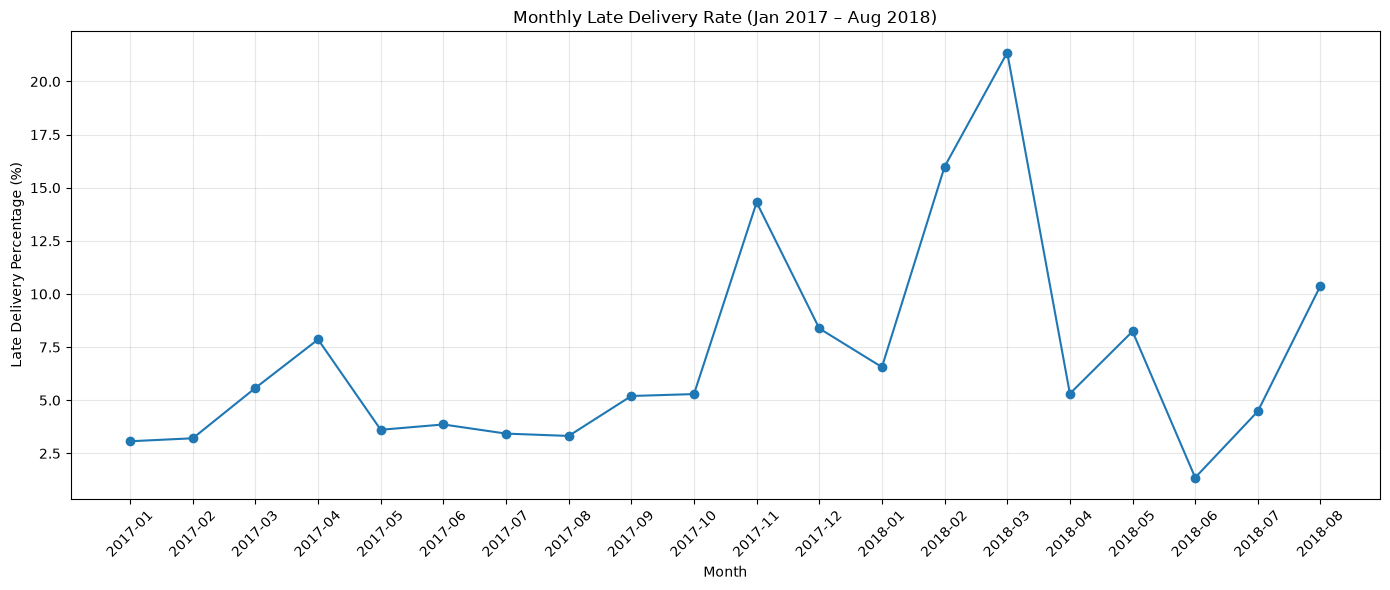

In [44]:
plt.figure(figsize=(14, 6))

plt.plot(
    complete_monthly_performance.index.astype(str),
    complete_monthly_performance["late_percentage"],
    marker="o"
)

plt.title("Monthly Late Delivery Rate (Jan 2017 – Aug 2018)")

plt.xlabel("Month")
plt.ylabel("Late Delivery Percentage (%)")

plt.xticks(rotation=45)

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

In [45]:
# Display the three best and worst performing months

columns_to_show = [
    "total_orders",
    "late_orders",
    "late_percentage"
]

print("BEST 3 MONTHS")
display(
    complete_monthly_performance
    .sort_values("late_percentage")
    .head(3)[columns_to_show]
)

print("WORST 3 MONTHS")
display(
    complete_monthly_performance
    .sort_values("late_percentage", ascending=False)
    .head(3)[columns_to_show]
)

BEST 3 MONTHS


,total_orders,late_orders,late_percentage
purchase_month,,,
2018-06,6096,83,1.36
2017-01,750,23,3.07
2017-02,1653,53,3.21


WORST 3 MONTHS


,total_orders,late_orders,late_percentage
purchase_month,,,
2018-03,7003,1496,21.36
2018-02,6555,1048,15.99
2017-11,7288,1043,14.31


In [46]:
# Load additional business datasets

items = pd.read_csv(
    project_folder / "data" / "raw" / "olist_order_items_dataset.csv"
)

products = pd.read_csv(
    project_folder / "data" / "raw" / "olist_products_dataset.csv"
)

sellers = pd.read_csv(
    project_folder / "data" / "raw" / "olist_sellers_dataset.csv"
)

category_translation = pd.read_csv(
    project_folder / "data" / "raw" / "product_category_name_translation.csv"
)

print("All four datasets loaded successfully!")

All four datasets loaded successfully!


In [47]:
# Check the size of each dataset

print("ORDER ITEMS:", items.shape)

print("PRODUCTS:", products.shape)

print("SELLERS:", sellers.shape)

print("CATEGORY TRANSLATION:", category_translation.shape)

ORDER ITEMS: (112650, 7)
PRODUCTS: (32951, 9)
SELLERS: (3095, 4)
CATEGORY TRANSLATION: (71, 2)


In [48]:
# Display the first five rows of each dataset

print("ORDER ITEMS")
display(items.head())

print("PRODUCTS")
display(products.head())

print("SELLERS")
display(sellers.head())

print("CATEGORY TRANSLATION")
display(category_translation.head())

ORDER ITEMS


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


PRODUCTS


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


SELLERS


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


CATEGORY TRANSLATION


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


In [49]:
# Display column names of all four datasets

print("ORDER ITEMS COLUMNS:")
print(items.columns.tolist())

print("\nPRODUCTS COLUMNS:")
print(products.columns.tolist())

print("\nSELLERS COLUMNS:")
print(sellers.columns.tolist())

print("\nCATEGORY TRANSLATION COLUMNS:")
print(category_translation.columns.tolist())

ORDER ITEMS COLUMNS:
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

PRODUCTS COLUMNS:
['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']

SELLERS COLUMNS:
['seller_id', 'seller_zip_code_prefix', 'seller_city', 'seller_state']

CATEGORY TRANSLATION COLUMNS:
['product_category_name', 'product_category_name_english']


In [50]:
# Check duplicate IDs in dimension datasets

print(
    "Duplicate product IDs:",
    products["product_id"].duplicated().sum()
)

print(
    "Duplicate seller IDs:",
    sellers["seller_id"].duplicated().sum()
)

print(
    "Duplicate category names:",
    category_translation["product_category_name"].duplicated().sum()
)

print(
    "Duplicate order item combinations:",
    items.duplicated(
        subset=["order_id", "order_item_id"]
    ).sum()
)

Duplicate product IDs: 0
Duplicate seller IDs: 0
Duplicate category names: 0
Duplicate order item combinations: 0


In [51]:
# Check missing product categories

print(
    "Missing product categories:",
    products["product_category_name"].isnull().sum()
)

print(
    "Missing product IDs:",
    products["product_id"].isnull().sum()
)

print(
    "Missing seller IDs:",
    sellers["seller_id"].isnull().sum()
)

Missing product categories: 610
Missing product IDs: 0
Missing seller IDs: 0


In [52]:
# Check whether all order item product IDs exist in products

missing_product_matches = (
    ~items["product_id"].isin(products["product_id"])
).sum()

print(
    "Order items with unmatched product IDs:",
    missing_product_matches
)

Order items with unmatched product IDs: 0


In [53]:
# Check whether all order item seller IDs exist in sellers

missing_seller_matches = (
    ~items["seller_id"].isin(sellers["seller_id"])
).sum()

print(
    "Order items with unmatched seller IDs:",
    missing_seller_matches
)

Order items with unmatched seller IDs: 0


In [54]:
# Display products with missing categories

missing_category_products = products[
    products["product_category_name"].isnull()
]

print(
    "Products with missing categories:",
    len(missing_category_products)
)

missing_category_products.head(10)

Products with missing categories: 610


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
105,a41e356c76fab66334f36de622ecbd3a,NaN,NaN,NaN,NaN,650.0,17.0,14.0,12.0
128,d8dee61c2034d6d075997acef1870e9b,NaN,NaN,NaN,NaN,300.0,16.0,7.0,20.0
145,56139431d72cd51f19eb9f7dae4d1617,NaN,NaN,NaN,NaN,200.0,20.0,20.0,20.0
154,46b48281eb6d663ced748f324108c733,NaN,NaN,NaN,NaN,18500.0,41.0,30.0,41.0
197,5fb61f482620cb672f5e586bb132eae9,NaN,NaN,NaN,NaN,300.0,35.0,7.0,12.0
244,e10758160da97891c2fdcbc35f0f031d,NaN,NaN,NaN,NaN,2200.0,16.0,2.0,11.0
294,39e3b9b12cd0bf8ee681bbc1c130feb5,NaN,NaN,NaN,NaN,300.0,16.0,7.0,11.0
299,794de06c32a626a5692ff50e4985d36f,NaN,NaN,NaN,NaN,300.0,18.0,8.0,14.0
347,7af3e2da474486a3519b0cba9dea8ad9,NaN,NaN,NaN,NaN,200.0,22.0,14.0,14.0
428,629beb8e7317703dcc5f35b5463fd20e,NaN,NaN,NaN,NaN,1400.0,25.0,25.0,25.0


In [55]:
# Find product categories without English translations

untranslated_categories = products[
    products["product_category_name"].notnull() &
    ~products["product_category_name"].isin(
        category_translation["product_category_name"]
    )
]

print(
    "Categories without English translations:",
    untranslated_categories["product_category_name"].nunique()
)

Categories without English translations: 2


In [56]:
missing_product_matches = (
    ~items["product_id"].isin(products["product_id"])
).sum()

print("Unmatched product IDs:", missing_product_matches)

Unmatched product IDs: 0


In [57]:
missing_seller_matches = (
    ~items["seller_id"].isin(sellers["seller_id"])
).sum()

print("Unmatched seller IDs:", missing_seller_matches)

Unmatched seller IDs: 0


In [58]:
# Join Order Items with Products

items_products = items.merge(
    products[
        [
            "product_id",
            "product_category_name"
        ]
    ],
    on="product_id",
    how="left",
    validate="many_to_one",
    indicator=True
)

print("Order Items and Products joined successfully!")

Order Items and Products joined successfully!


In [59]:
# Check joined dataset dimensions

print("Original Order Items:", items.shape)

print("Joined Dataset:", items_products.shape)

Original Order Items: (112650, 7)
Joined Dataset: (112650, 9)


In [60]:
# Check product matching results

print(
    items_products["_merge"].value_counts()
)

_merge
both          112650
left_only          0
right_only         0
Name: count, dtype: int64


In [61]:
# Display first 10 joined records

items_products.head(10)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,_merge
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff,both
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop,both
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,moveis_decoracao,both
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumaria,both
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,ferramentas_jardim,both
5,00048cc3ae777c65dbb7d2a0634bc1ea,1,ef92defde845ab8450f9d70c526ef70f,6426d21aca402a131fc0a5d0960a3c90,2017-05-23 03:55:27,21.90,12.69,utilidades_domesticas,both
6,00054e8431b9d7675808bcb819fb4a32,1,8d4f2bb7e93e6710a28f34fa83ee7d28,7040e82f899a04d1b434b795a43b4617,2017-12-14 12:10:31,19.90,11.85,telefonia,both
7,000576fe39319847cbb9d288c5617fa6,1,557d850972a7d6f792fd18ae1400d9b6,5996cddab893a4652a15592fb58ab8db,2018-07-10 12:30:45,810.00,70.75,ferramentas_jardim,both
8,0005a1a1728c9d785b8e2b08b904576c,1,310ae3c140ff94b03219ad0adc3c778f,a416b6a846a11724393025641d4edd5e,2018-03-26 18:31:29,145.95,11.65,beleza_saude,both
9,0005f50442cb953dcd1d21e1fb923495,1,4535b0e1091c278dfd193e5a1d63b39f,ba143b05f0110f0dc71ad71b4466ce92,2018-07-06 14:10:56,53.99,11.40,livros_tecnicos,both


In [62]:
# Display first 10 joined records

items_products.head(10)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,_merge
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff,both
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop,both
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,moveis_decoracao,both
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumaria,both
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,ferramentas_jardim,both
5,00048cc3ae777c65dbb7d2a0634bc1ea,1,ef92defde845ab8450f9d70c526ef70f,6426d21aca402a131fc0a5d0960a3c90,2017-05-23 03:55:27,21.90,12.69,utilidades_domesticas,both
6,00054e8431b9d7675808bcb819fb4a32,1,8d4f2bb7e93e6710a28f34fa83ee7d28,7040e82f899a04d1b434b795a43b4617,2017-12-14 12:10:31,19.90,11.85,telefonia,both
7,000576fe39319847cbb9d288c5617fa6,1,557d850972a7d6f792fd18ae1400d9b6,5996cddab893a4652a15592fb58ab8db,2018-07-10 12:30:45,810.00,70.75,ferramentas_jardim,both
8,0005a1a1728c9d785b8e2b08b904576c,1,310ae3c140ff94b03219ad0adc3c778f,a416b6a846a11724393025641d4edd5e,2018-03-26 18:31:29,145.95,11.65,beleza_saude,both
9,0005f50442cb953dcd1d21e1fb923495,1,4535b0e1091c278dfd193e5a1d63b39f,ba143b05f0110f0dc71ad71b4466ce92,2018-07-06 14:10:56,53.99,11.40,livros_tecnicos,both


In [63]:
# Compare dataset dimensions

print("Original Order Items:", items.shape)

print("Joined Dataset:", items_products.shape)

Original Order Items: (112650, 7)
Joined Dataset: (112650, 9)


In [64]:
# Check matching results

print(items_products["_merge"].value_counts())

_merge
both          112650
left_only          0
right_only         0
Name: count, dtype: int64


In [65]:
# Display important joined information

items_products[
    [
        "order_id",
        "product_id",
        "seller_id",
        "price",
        "product_category_name",
        "_merge"
    ]
].head(10)

,order_id,product_id,seller_id,price,product_category_name,_merge
0,00010242fe8c5a6d1ba2dd792cb16214,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,58.90,cool_stuff,both
1,00018f77f2f0320c557190d7a144bdd3,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,239.90,pet_shop,both
2,000229ec398224ef6ca0657da4fc703e,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,199.00,moveis_decoracao,both
3,00024acbcdf0a6daa1e931b038114c75,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,12.99,perfumaria,both
4,00042b26cf59d7ce69dfabb4e55b4fd9,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,199.90,ferramentas_jardim,both
5,00048cc3ae777c65dbb7d2a0634bc1ea,ef92defde845ab8450f9d70c526ef70f,6426d21aca402a131fc0a5d0960a3c90,21.90,utilidades_domesticas,both
6,00054e8431b9d7675808bcb819fb4a32,8d4f2bb7e93e6710a28f34fa83ee7d28,7040e82f899a04d1b434b795a43b4617,19.90,telefonia,both
7,000576fe39319847cbb9d288c5617fa6,557d850972a7d6f792fd18ae1400d9b6,5996cddab893a4652a15592fb58ab8db,810.00,ferramentas_jardim,both
8,0005a1a1728c9d785b8e2b08b904576c,310ae3c140ff94b03219ad0adc3c778f,a416b6a846a11724393025641d4edd5e,145.95,beleza_saude,both
9,0005f50442cb953dcd1d21e1fb923495,4535b0e1091c278dfd193e5a1d63b39f,ba143b05f0110f0dc71ad71b4466ce92,53.99,livros_tecnicos,both


In [66]:
# Join seller information with items and products

items_products_sellers = items_products.merge(
    sellers[
        [
            "seller_id",
            "seller_city",
            "seller_state"
        ]
    ],
    on="seller_id",
    how="left",
    validate="many_to_one",
    indicator="seller_match"
)

print("Seller information joined successfully!")

Seller information joined successfully!


In [67]:
# Compare dataset dimensions

print("Before seller join:", items_products.shape)

print("After seller join:", items_products_sellers.shape)

Before seller join: (112650, 9)
After seller join: (112650, 12)


In [68]:
# Check seller matching results

print(items_products_sellers["seller_match"].value_counts())

seller_match
both          112650
left_only          0
right_only         0
Name: count, dtype: int64


In [69]:
# Display order, product and seller information

items_products_sellers[
    [
        "order_id",
        "product_id",
        "product_category_name",
        "seller_id",
        "seller_city",
        "seller_state",
        "price",
        "seller_match"
    ]
].head(10)

,order_id,product_id,product_category_name,seller_id,seller_city,seller_state,price,seller_match
0,00010242fe8c5a6d1ba2dd792cb16214,4244733e06e7ecb4970a6e2683c13e61,cool_stuff,48436dade18ac8b2bce089ec2a041202,volta redonda,SP,58.90,both
1,00018f77f2f0320c557190d7a144bdd3,e5f2d52b802189ee658865ca93d83a8f,pet_shop,dd7ddc04e1b6c2c614352b383efe2d36,sao paulo,SP,239.90,both
2,000229ec398224ef6ca0657da4fc703e,c777355d18b72b67abbeef9df44fd0fd,moveis_decoracao,5b51032eddd242adc84c38acab88f23d,borda da mata,MG,199.00,both
3,00024acbcdf0a6daa1e931b038114c75,7634da152a4610f1595efa32f14722fc,perfumaria,9d7a1d34a5052409006425275ba1c2b4,franca,SP,12.99,both
4,00042b26cf59d7ce69dfabb4e55b4fd9,ac6c3623068f30de03045865e4e10089,ferramentas_jardim,df560393f3a51e74553ab94004ba5c87,loanda,PR,199.90,both
5,00048cc3ae777c65dbb7d2a0634bc1ea,ef92defde845ab8450f9d70c526ef70f,utilidades_domesticas,6426d21aca402a131fc0a5d0960a3c90,ribeirao preto,SP,21.90,both
6,00054e8431b9d7675808bcb819fb4a32,8d4f2bb7e93e6710a28f34fa83ee7d28,telefonia,7040e82f899a04d1b434b795a43b4617,sao paulo,SP,19.90,both
7,000576fe39319847cbb9d288c5617fa6,557d850972a7d6f792fd18ae1400d9b6,ferramentas_jardim,5996cddab893a4652a15592fb58ab8db,presidente prudente,SP,810.00,both
8,0005a1a1728c9d785b8e2b08b904576c,310ae3c140ff94b03219ad0adc3c778f,beleza_saude,a416b6a846a11724393025641d4edd5e,sao paulo,SP,145.95,both
9,0005f50442cb953dcd1d21e1fb923495,4535b0e1091c278dfd193e5a1d63b39f,livros_tecnicos,ba143b05f0110f0dc71ad71b4466ce92,sao paulo,SP,53.99,both


In [70]:
# Join English category translations

items_full = items_products_sellers.merge(
    category_translation,
    on="product_category_name",
    how="left",
    validate="many_to_one",
    indicator="translation_match"
)

print("English category translations joined successfully!")

English category translations joined successfully!


In [71]:
# Check dataset size and matching results

print("Before translation:", items_products_sellers.shape)

print("After translation:", items_full.shape)

print("\nTranslation matching results:")
print(items_full["translation_match"].value_counts())

Before translation: (112650, 12)
After translation: (112650, 14)

Translation matching results:
translation_match
both          111023
left_only       1627
right_only         0
Name: count, dtype: int64


In [72]:
# Create business-friendly English category names

items_full["category_english"] = (
    items_full["product_category_name_english"].fillna(
        items_full["product_category_name"]
    )
)

items_full["category_english"] = (
    items_full["category_english"].fillna(
        "Unknown Category"
    )
)

print("Category names prepared successfully!")

Category names prepared successfully!


In [73]:
# Display product and category information

items_full[
    [
        "order_id",
        "product_id",
        "seller_id",
        "seller_city",
        "seller_state",
        "product_category_name",
        "product_category_name_english",
        "category_english"
    ]
].head(10)

,order_id,product_id,seller_id,seller_city,seller_state,product_category_name,product_category_name_english,category_english
0,00010242fe8c5a6d1ba2dd792cb16214,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,volta redonda,SP,cool_stuff,cool_stuff,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,sao paulo,SP,pet_shop,pet_shop,pet_shop
2,000229ec398224ef6ca0657da4fc703e,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,borda da mata,MG,moveis_decoracao,furniture_decor,furniture_decor
3,00024acbcdf0a6daa1e931b038114c75,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,franca,SP,perfumaria,perfumery,perfumery
4,00042b26cf59d7ce69dfabb4e55b4fd9,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,loanda,PR,ferramentas_jardim,garden_tools,garden_tools
5,00048cc3ae777c65dbb7d2a0634bc1ea,ef92defde845ab8450f9d70c526ef70f,6426d21aca402a131fc0a5d0960a3c90,ribeirao preto,SP,utilidades_domesticas,housewares,housewares
6,00054e8431b9d7675808bcb819fb4a32,8d4f2bb7e93e6710a28f34fa83ee7d28,7040e82f899a04d1b434b795a43b4617,sao paulo,SP,telefonia,telephony,telephony
7,000576fe39319847cbb9d288c5617fa6,557d850972a7d6f792fd18ae1400d9b6,5996cddab893a4652a15592fb58ab8db,presidente prudente,SP,ferramentas_jardim,garden_tools,garden_tools
8,0005a1a1728c9d785b8e2b08b904576c,310ae3c140ff94b03219ad0adc3c778f,a416b6a846a11724393025641d4edd5e,sao paulo,SP,beleza_saude,health_beauty,health_beauty
9,0005f50442cb953dcd1d21e1fb923495,4535b0e1091c278dfd193e5a1d63b39f,ba143b05f0110f0dc71ad71b4466ce92,sao paulo,SP,livros_tecnicos,books_technical,books_technical


In [74]:
# Check prepared category names

print(
    "Missing prepared category names:",
    items_full["category_english"].isnull().sum()
)

print(
    "Unknown category order items:",
    (items_full["category_english"] == "Unknown Category").sum()
)

print(
    "Total order-item records:",
    len(items_full)
)

Missing prepared category names: 0
Unknown category order items: 1603
Total order-item records: 112650


In [75]:
# Select delivery information needed for the join

delivery_info = analysis_deliveries[
    [
        "order_id",
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
        "delivery_days",
        "is_late"
    ]
].copy()

print("Delivery information prepared!")

print("Delivery records:", len(delivery_info))

Delivery information prepared!
Delivery records: 96470


In [76]:
# Verify that each order appears once in delivery_info

print(
    "Duplicate delivery order IDs:",
    delivery_info["order_id"].duplicated().sum()
)

Duplicate delivery order IDs: 0


In [77]:
# Join product and seller data with delivery information

marketplace_data = items_full.merge(
    delivery_info,
    on="order_id",
    how="left",
    validate="many_to_one",
    indicator="delivery_match"
)

print("Marketplace analytical dataset created!")

Marketplace analytical dataset created!


In [78]:
# Check dataset dimensions

print("Before join:", items_full.shape)

print("After join:", marketplace_data.shape)

print("\nDelivery matching results:")

print(
    marketplace_data["delivery_match"].value_counts()
)

Before join: (112650, 15)
After join: (112650, 21)

Delivery matching results:
delivery_match
both          110189
left_only       2461
right_only         0
Name: count, dtype: int64


In [79]:
# Display important columns

marketplace_data[
    [
        "order_id",
        "product_id",
        "seller_id",
        "seller_city",
        "seller_state",
        "category_english",
        "price",
        "delivery_days",
        "is_late",
        "delivery_match"
    ]
].head(10)

,order_id,product_id,seller_id,seller_city,seller_state,category_english,price,delivery_days,is_late,delivery_match
0,00010242fe8c5a6d1ba2dd792cb16214,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,volta redonda,SP,cool_stuff,58.90,7.614421,False,both
1,00018f77f2f0320c557190d7a144bdd3,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,sao paulo,SP,pet_shop,239.90,16.216181,False,both
2,000229ec398224ef6ca0657da4fc703e,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,borda da mata,MG,furniture_decor,199.00,7.948437,False,both
3,00024acbcdf0a6daa1e931b038114c75,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,franca,SP,perfumery,12.99,6.147269,False,both
4,00042b26cf59d7ce69dfabb4e55b4fd9,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,loanda,PR,garden_tools,199.90,25.114352,False,both
5,00048cc3ae777c65dbb7d2a0634bc1ea,ef92defde845ab8450f9d70c526ef70f,6426d21aca402a131fc0a5d0960a3c90,ribeirao preto,SP,housewares,21.90,6.668067,False,both
6,00054e8431b9d7675808bcb819fb4a32,8d4f2bb7e93e6710a28f34fa83ee7d28,7040e82f899a04d1b434b795a43b4617,sao paulo,SP,telephony,19.90,8.423495,False,both
7,000576fe39319847cbb9d288c5617fa6,557d850972a7d6f792fd18ae1400d9b6,5996cddab893a4652a15592fb58ab8db,presidente prudente,SP,garden_tools,810.00,5.080324,False,both
8,0005a1a1728c9d785b8e2b08b904576c,310ae3c140ff94b03219ad0adc3c778f,a416b6a846a11724393025641d4edd5e,sao paulo,SP,health_beauty,145.95,9.984005,True,both
9,0005f50442cb953dcd1d21e1fb923495,4535b0e1091c278dfd193e5a1d63b39f,ba143b05f0110f0dc71ad71b4466ce92,sao paulo,SP,books_technical,53.99,2.145046,False,both


In [80]:
# Select order items with valid delivery information

category_data = marketplace_data[
    marketplace_data["delivery_match"] == "both"
].copy()

print("Records available for category analysis:", len(category_data))

print(
    "Unique orders:",
    category_data["order_id"].nunique()
)

Records available for category analysis: 110189
Unique orders: 96470


In [81]:
# Keep one record per order and product category

category_orders = category_data.drop_duplicates(
    subset=["order_id", "category_english"]
).copy()

print("Order-category combinations:", len(category_orders))

category_orders[
    ["order_id", "category_english", "is_late"]
].head(10)

Order-category combinations: 97268


,order_id,category_english,is_late
0,00010242fe8c5a6d1ba2dd792cb16214,cool_stuff,False
1,00018f77f2f0320c557190d7a144bdd3,pet_shop,False
2,000229ec398224ef6ca0657da4fc703e,furniture_decor,False
3,00024acbcdf0a6daa1e931b038114c75,perfumery,False
4,00042b26cf59d7ce69dfabb4e55b4fd9,garden_tools,False
5,00048cc3ae777c65dbb7d2a0634bc1ea,housewares,False
6,00054e8431b9d7675808bcb819fb4a32,telephony,False
7,000576fe39319847cbb9d288c5617fa6,garden_tools,False
8,0005a1a1728c9d785b8e2b08b904576c,health_beauty,True
9,0005f50442cb953dcd1d21e1fb923495,books_technical,False


In [82]:
# Calculate late delivery performance by category

category_performance = category_orders.groupby(
    "category_english"
).agg(
    total_orders=("order_id", "nunique"),
    late_orders=("is_late", "sum")
).reset_index()

# Calculate late delivery rate

category_performance["late_rate"] = (
    category_performance["late_orders"]
    / category_performance["total_orders"] * 100
).round(2)

category_performance.head(10)

,category_english,total_orders,late_orders,late_rate
0,Unknown Category,1392,127,9.12
1,agro_industry_and_commerce,177,9,5.08
2,air_conditioning,246,10,4.07
3,art,195,15,7.69
4,arts_and_craftmanship,23,2,8.7
5,audio,348,45,12.93
6,auto,3809,328,8.61
7,baby,2809,258,9.18
8,bed_bath_table,9272,811,8.75
9,books_general_interest,495,34,6.87


In [83]:
# Keep categories with at least 100 orders

category_performance_filtered = category_performance[
    category_performance["total_orders"] >= 100
].copy()

# Rank categories from highest to lowest late rate

top_late_categories = category_performance_filtered.sort_values(
    by="late_rate",
    ascending=False
).head(10)

top_late_categories

,category_english,total_orders,late_orders,late_rate
5,audio,348,45,12.93
34,fashion_underwear_beach,117,15,12.82
11,books_technical,256,28,10.94
48,home_confort,392,41,10.46
37,food,441,44,9.98
27,electronics,2517,247,9.81
13,christmas_supplies,125,12,9.6
7,baby,2809,258,9.18
58,office_furniture,1254,115,9.17
0,Unknown Category,1392,127,9.12


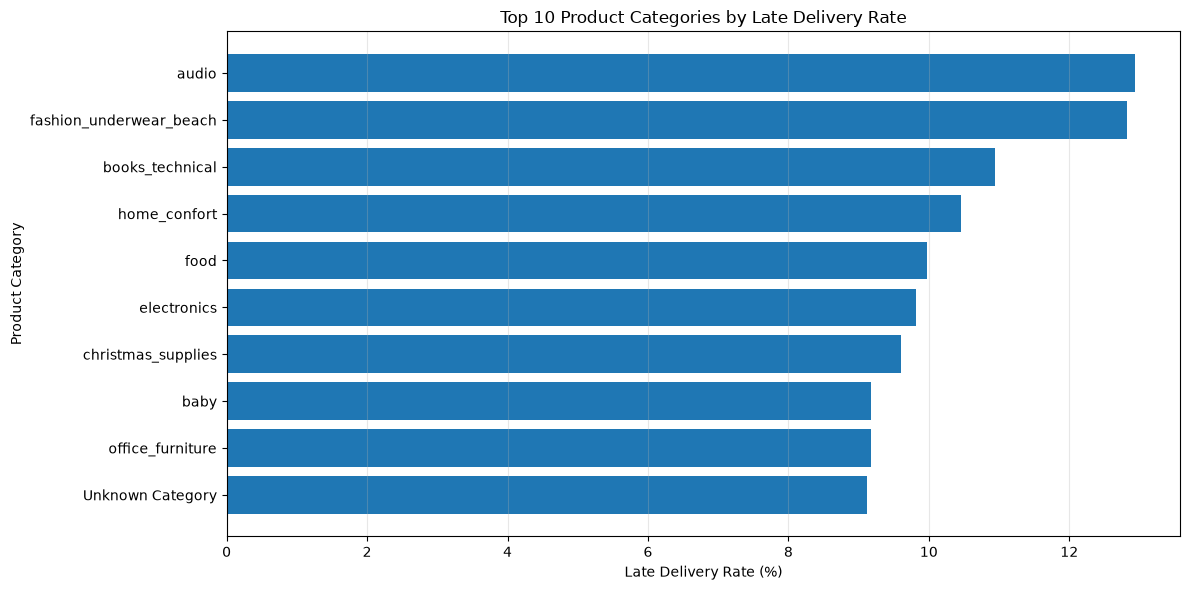

In [84]:
# Visualize the 10 categories with highest late delivery rates

plt.figure(figsize=(12, 6))

plt.barh(
    top_late_categories["category_english"],
    top_late_categories["late_rate"]
)

plt.xlabel("Late Delivery Rate (%)")

plt.ylabel("Product Category")

plt.title("Top 10 Product Categories by Late Delivery Rate")

plt.gca().invert_yaxis()

plt.grid(axis="x", alpha=0.3)

plt.tight_layout()

plt.show()

In [85]:
# Create dataset for seller analysis

seller_data = marketplace_data[
    marketplace_data["delivery_match"] == "both"
].copy()

print("Total order-item records:", len(seller_data))

print(
    "Unique sellers:",
    seller_data["seller_id"].nunique()
)

print(
    "Unique orders:",
    seller_data["order_id"].nunique()
)

Total order-item records: 110189
Unique sellers: 2970
Unique orders: 96470


In [86]:
# Keep one record per seller and order

seller_orders = seller_data.drop_duplicates(
    subset=["order_id", "seller_id"]
).copy()

print("Seller-order combinations:", len(seller_orders))

Seller-order combinations: 97811


In [87]:
# Calculate delivery performance by seller

seller_performance = seller_orders.groupby(
    "seller_id"
).agg(
    total_orders=("order_id", "nunique"),
    late_orders=("is_late", "sum"),
    average_delivery_days=("delivery_days", "mean")
).reset_index()

# Calculate late delivery percentage

seller_performance["late_rate"] = (
    seller_performance["late_orders"]
    / seller_performance["total_orders"] * 100
).round(2)

seller_performance.head(10)

,seller_id,total_orders,late_orders,average_delivery_days,late_rate
0,0015a82c2db000af6aaaf3ae2ecb0532,3,0,10.793885,0.0
1,001cca7ae9ae17fb1caed9dfb1094831,195,13,13.405805,6.67
2,002100f778ceb8431b7a1020ff7ab48f,50,9,16.386809,18.0
3,003554e2dce176b5555353e4f3555ac8,1,False,4.646806,0.0
4,004c9cd9d87a3c30c522c48c4fc07416,156,13,14.811330,8.33
5,00720abe85ba0859807595bbf045a33b,13,2,11.786855,15.38
6,00ab3eff1b5192e5f1a63bcecfee11c8,1,False,9.052488,0.0
7,00d8b143d12632bad99c0ad66ad52825,1,False,7.233345,0.0
8,00ee68308b45bc5e2660cd833c3f81cc,135,12,9.619417,8.89
9,00fc707aaaad2d31347cf883cd2dfe10,103,5,15.109578,4.85


In [88]:
# Filter sellers with at least 100 orders

seller_performance_filtered = seller_performance[
    seller_performance["total_orders"] >= 100
].copy()

# Identify top 10 sellers by late delivery rate

top_late_sellers = seller_performance_filtered.sort_values(
    by="late_rate",
    ascending=False
).head(10)

top_late_sellers

,seller_id,total_orders,late_orders,average_delivery_days,late_rate
79,06a2c3af7b3aee5d69171b0e14f0ee87,389,90,17.728176,23.14
323,1ca7077d890b907f89be8c954a02686a,108,24,15.536054,22.22
1606,88460e8ebdecbfecb5f9601833981930,246,48,17.799441,19.51
2657,e5a3438891c0bfdb9394643f95273d8e,216,40,15.663078,18.52
2404,cd68562d3f44870c08922d380acae552,122,22,16.261455,18.03
1532,8160255418d5aaa7dbdc9f4c64ebda44,380,63,16.249577,16.58
513,2c9e548be18521d1c43cde1c582c6de8,124,20,13.678750,16.13
2577,dd7ddc04e1b6c2c614352b383efe2d36,121,19,15.020833,15.7
2877,f7ba60f8c3f99e7ee4042fdef03b70c4,218,34,13.405900,15.6
781,431af27f296bc6519d890aa5a05fdb11,116,18,17.234933,15.52


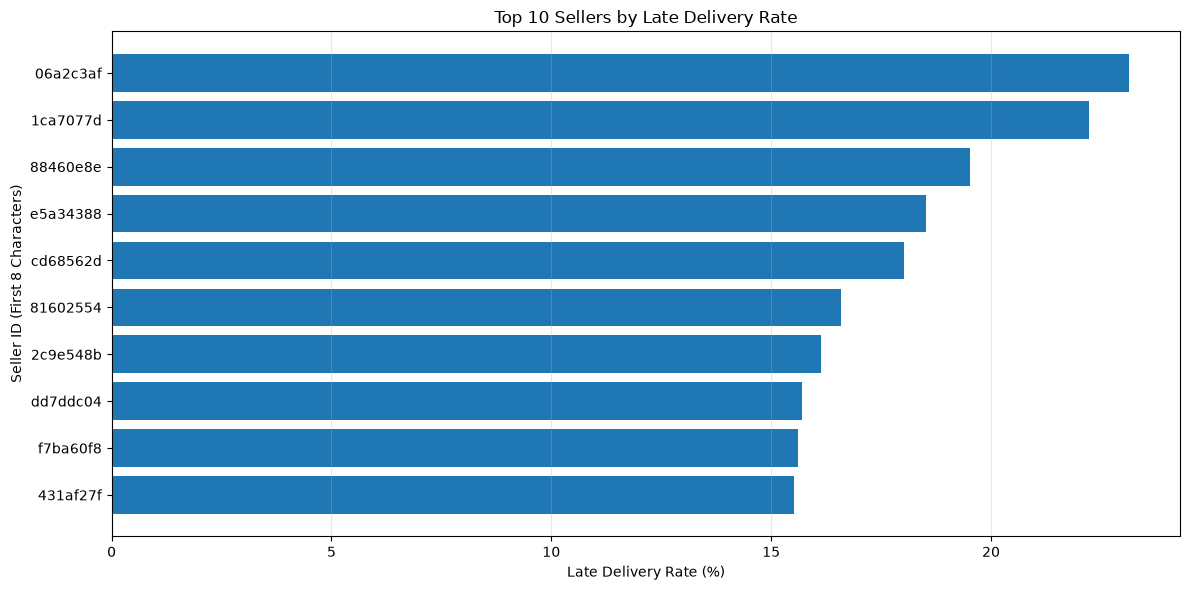

In [89]:
# Visualize sellers with highest late delivery rates

plt.figure(figsize=(12, 6))

plt.barh(
    top_late_sellers["seller_id"].str[:8],
    top_late_sellers["late_rate"]
)

plt.xlabel("Late Delivery Rate (%)")
plt.ylabel("Seller ID (First 8 Characters)")
plt.title("Top 10 Sellers by Late Delivery Rate")

plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [90]:
# Display seller locations

print("Number of seller states:",
      seller_orders["seller_state"].nunique())

print("\nSeller states:")
print(seller_orders["seller_state"].unique())

# Display sample seller records
seller_orders[
    ["order_id", "seller_id", "seller_city", "seller_state", "is_late"]
].head(10)

Number of seller states: 22

Seller states:
<StringArray>
['SP', 'MG', 'PR', 'SC', 'DF', 'RS', 'RJ', 'GO', 'MA', 'ES', 'BA', 'PI', 'RO',
 'MT', 'CE', 'RN', 'PE', 'SE', 'MS', 'PB', 'PA', 'AM']
Length: 22, dtype: str


,order_id,seller_id,seller_city,seller_state,is_late
0,00010242fe8c5a6d1ba2dd792cb16214,48436dade18ac8b2bce089ec2a041202,volta redonda,SP,False
1,00018f77f2f0320c557190d7a144bdd3,dd7ddc04e1b6c2c614352b383efe2d36,sao paulo,SP,False
2,000229ec398224ef6ca0657da4fc703e,5b51032eddd242adc84c38acab88f23d,borda da mata,MG,False
3,00024acbcdf0a6daa1e931b038114c75,9d7a1d34a5052409006425275ba1c2b4,franca,SP,False
4,00042b26cf59d7ce69dfabb4e55b4fd9,df560393f3a51e74553ab94004ba5c87,loanda,PR,False
5,00048cc3ae777c65dbb7d2a0634bc1ea,6426d21aca402a131fc0a5d0960a3c90,ribeirao preto,SP,False
6,00054e8431b9d7675808bcb819fb4a32,7040e82f899a04d1b434b795a43b4617,sao paulo,SP,False
7,000576fe39319847cbb9d288c5617fa6,5996cddab893a4652a15592fb58ab8db,presidente prudente,SP,False
8,0005a1a1728c9d785b8e2b08b904576c,a416b6a846a11724393025641d4edd5e,sao paulo,SP,True
9,0005f50442cb953dcd1d21e1fb923495,ba143b05f0110f0dc71ad71b4466ce92,sao paulo,SP,False


In [91]:
# Keep one record per order and seller state

state_orders = seller_orders.drop_duplicates(
    subset=["order_id", "seller_state"]
).copy()

print("Order-state combinations:", len(state_orders))

Order-state combinations: 96986


In [92]:
# Calculate state-level delivery performance

state_performance = state_orders.groupby(
    "seller_state"
).agg(
    total_orders=("order_id", "nunique"),
    late_orders=("is_late", "sum"),
    average_delivery_days=("delivery_days", "mean")
).reset_index()

# Calculate late delivery percentage

state_performance["late_rate"] = (
    state_performance["late_orders"]
    / state_performance["total_orders"] * 100
).round(2)

state_performance["average_delivery_days"] = (
    state_performance["average_delivery_days"].round(2)
)

state_performance

,seller_state,total_orders,late_orders,average_delivery_days,late_rate
0,AM,3,2,47.84,66.67
1,BA,550,32,13.88,5.82
2,CE,87,8,17.64,9.2
3,DF,808,49,12.46,6.06
4,ES,310,22,13.08,7.1
5,GO,451,18,12.86,3.99
6,MA,389,90,17.73,23.14
7,MG,7733,432,12.83,5.59
8,MS,49,4,12.17,8.16
9,MT,136,6,14.75,4.41


In [93]:
# Filter states with at least 100 orders

state_performance_filtered = state_performance[
    state_performance["total_orders"] >= 100
].copy()

# Sort states by late delivery rate

top_late_states = state_performance_filtered.sort_values(
    by="late_rate",
    ascending=False
)

top_late_states[
    ["seller_state", "total_orders", "late_orders", "late_rate"]
]

,seller_state,total_orders,late_orders,late_rate
6,MA,389,90,23.14
21,SP,68635,6002,8.74
15,RJ,4227,355,8.4
4,ES,310,22,7.1
14,PR,7512,485,6.46
3,DF,808,49,6.06
19,SC,3603,215,5.97
1,BA,550,32,5.82
7,MG,7733,432,5.59
12,PE,403,18,4.47


In [94]:
# Load customer information

customers = pd.read_csv(
    project_folder / "data" / "raw" / "olist_customers_dataset.csv"
)

print("Customers dataset loaded successfully!")

print("Dataset dimensions:", customers.shape)

customers.head()

Customers dataset loaded successfully!
Dataset dimensions: (99441, 5)


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [95]:
# Check customer ID uniqueness

print("Total customer records:", len(customers))

print(
    "Unique customer IDs:",
    customers["customer_id"].nunique()
)

print(
    "Duplicate customer IDs:",
    customers["customer_id"].duplicated().sum()
)

print(
    "Missing customer states:",
    customers["customer_state"].isnull().sum()
)

Total customer records: 99441
Unique customer IDs: 99441
Duplicate customer IDs: 0
Missing customer states: 0


In [96]:
# Create customer delivery dataset

customer_delivery = analysis_deliveries.copy()

print("Customer delivery dataset created!")

print("Total delivery records:", len(customer_delivery))

print(
    "Missing customer IDs:",
    customer_delivery["customer_id"].isnull().sum()
)

Customer delivery dataset created!
Total delivery records: 96470
Missing customer IDs: 0


In [97]:
# Check customer IDs

customer_delivery[
    [
        "order_id",
        "customer_id",
        "order_status",
        "delivery_days",
        "is_late"
    ]
].head(10)

,order_id,customer_id,order_status,delivery_days,is_late
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,8.436574,False
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,13.782037,False
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,9.394213,False
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,13.208750,False
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2.873877,False
5,a4591c265e18cb1dcee52889e2d8acc3,503740e9ca751ccdda7ba28e9ab8f608,delivered,16.542245,False
7,6514b8ad8028c9f2cc2374ded245783f,9bdf08b4b3b52b5526ff42d37d47f222,delivered,9.989826,False
8,76c6e866289321a7c93b82b54852dc33,f54a9f0e6b351c431402b8461ea51999,delivered,9.818762,False
9,e69bfb5eb88e0ed6a785585b27e16dbf,31ad1d1b63eb9962463f764d4e6e0c9d,delivered,18.221852,False
10,e6ce16cb79ec1d90b1da9085a6118aeb,494dded5b201313c64ed7f100595b95c,delivered,12.650937,False


In [98]:
# Add customer location information

customer_delivery = customer_delivery.merge(
    customers[
        [
            "customer_id",
            "customer_unique_id",
            "customer_city",
            "customer_state"
        ]
    ],
    on="customer_id",
    how="left",
    validate="many_to_one",
    indicator="customer_match"
)

print("Customer locations joined successfully!")

print(customer_delivery["customer_match"].value_counts())

Customer locations joined successfully!
customer_match
both          96470
left_only         0
right_only        0
Name: count, dtype: int64


In [99]:
# Check customer states

print(
    "Number of customer states:",
    customer_delivery["customer_state"].nunique()
)

print("\nOrders by customer state:")

print(
    customer_delivery["customer_state"].value_counts()
)

Number of customer states: 27

Orders by customer state:
customer_state
SP    40494
RJ    12350
MG    11354
RS     5344
PR     4923
SC     3546
BA     3256
DF     2080
ES     1995
GO     1957
PE     1593
CE     1279
PA      946
MT      886
MA      717
MS      701
PB      517
PI      476
RN      474
AL      397
SE      335
TO      274
RO      243
AM      145
AC       80
AP       67
RR       41
Name: count, dtype: int64


In [100]:
# Calculate delivery performance by customer state

customer_state_performance = customer_delivery.groupby(
    "customer_state"
).agg(
    total_orders=("order_id", "nunique"),
    late_orders=("is_late", "sum"),
    average_delivery_days=("delivery_days", "mean")
).reset_index()

# Calculate late delivery rate
customer_state_performance["late_rate"] = (
    customer_state_performance["late_orders"]
    / customer_state_performance["total_orders"] * 100
).round(2)

# Round average delivery time
customer_state_performance["average_delivery_days"] = (
    customer_state_performance["average_delivery_days"].round(2)
)

customer_state_performance

,customer_state,total_orders,late_orders,average_delivery_days,late_rate
0,AC,80,3,21.04,3.75
1,AL,397,95,24.54,23.93
2,AM,145,6,26.43,4.14
3,AP,67,3,27.19,4.48
4,BA,3256,457,19.34,14.04
5,CE,1279,196,21.27,15.32
6,DF,2080,147,12.97,7.07
7,ES,1995,244,15.79,12.23
8,GO,1957,160,15.61,8.18
9,MA,717,141,21.57,19.67


In [101]:
# Filter states with at least 100 orders

customer_states_filtered = customer_state_performance[
    customer_state_performance["total_orders"] >= 100
].copy()

# Sort by highest late-delivery rate

top_customer_states = customer_states_filtered.sort_values(
    by="late_rate",
    ascending=False
)

top_customer_states[
    [
        "customer_state",
        "total_orders",
        "late_orders",
        "late_rate",
        "average_delivery_days"
    ]
]

,customer_state,total_orders,late_orders,late_rate,average_delivery_days
1,AL,397,95,23.93,24.54
9,MA,717,141,19.67,21.57
16,PI,476,76,15.97,19.46
5,CE,1279,196,15.32,21.27
24,SE,335,51,15.22,21.52
4,BA,3256,457,14.04,19.34
18,RJ,12350,1664,13.47,15.31
26,TO,274,35,12.77,17.66
13,PA,946,117,12.37,23.77
7,ES,1995,244,12.23,15.79


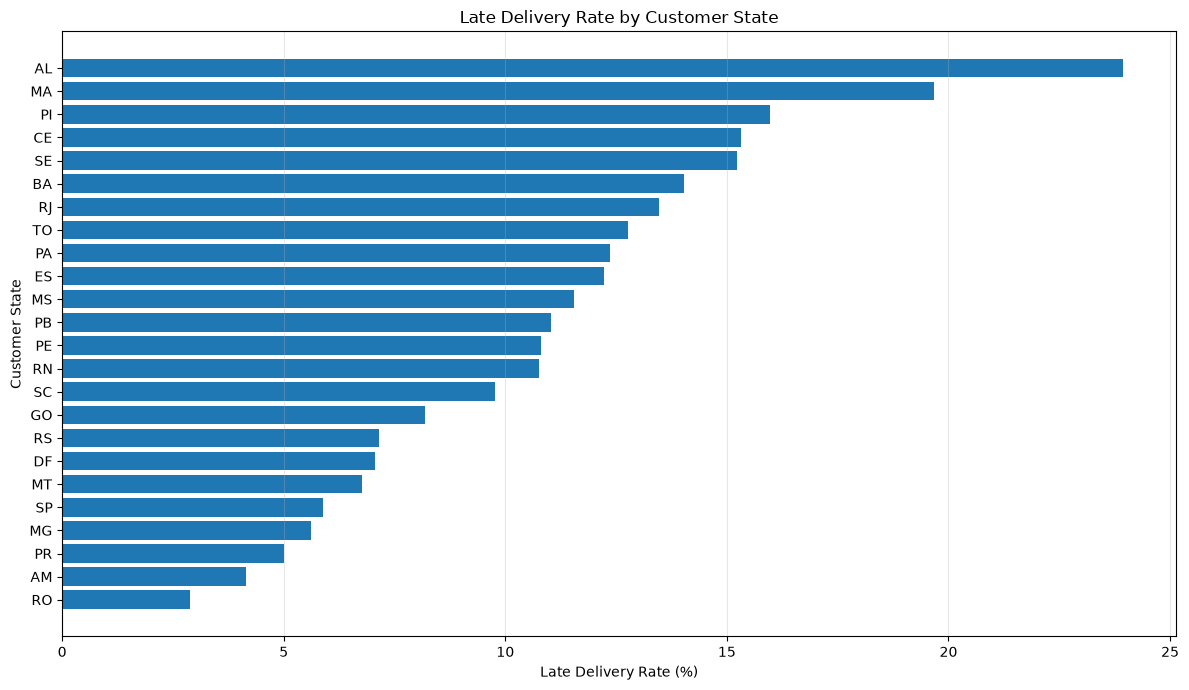

In [102]:
# Create customer state late-delivery chart

plt.figure(figsize=(12, 7))

plt.barh(
    top_customer_states["customer_state"],
    top_customer_states["late_rate"]
)

plt.xlabel("Late Delivery Rate (%)")
plt.ylabel("Customer State")

plt.title("Late Delivery Rate by Customer State")

plt.gca().invert_yaxis()

plt.grid(axis="x", alpha=0.3)

plt.tight_layout()

plt.show()

In [103]:
# Identify the highest and lowest late-delivery states

worst_state = top_customer_states.iloc[0]

best_state = top_customer_states.iloc[-1]

print("HIGHEST LATE DELIVERY STATE")
print("---------------------------")

print("State:", worst_state["customer_state"])
print("Total orders:", worst_state["total_orders"])
print("Late orders:", worst_state["late_orders"])
print("Late rate:", worst_state["late_rate"], "%")

print("\nLOWEST LATE DELIVERY STATE")
print("--------------------------")

print("State:", best_state["customer_state"])
print("Total orders:", best_state["total_orders"])
print("Late orders:", best_state["late_orders"])
print("Late rate:", best_state["late_rate"], "%")

HIGHEST LATE DELIVERY STATE
---------------------------
State: AL
Total orders: 397
Late orders: 95
Late rate: 23.93 %

LOWEST LATE DELIVERY STATE
--------------------------
State: RO
Total orders: 243
Late orders: 7
Late rate: 2.88 %


In [104]:
# Connect seller locations with customer locations

seller_customer = seller_orders[
    ["order_id", "seller_id", "seller_state"]
].merge(
    customer_delivery[
        ["order_id", "customer_state"]
    ],
    on="order_id",
    how="left",
    validate="many_to_one"
)

print("Seller and customer locations connected!")

print("Total seller-order records:", len(seller_customer))

print(
    "Missing customer states:",
    seller_customer["customer_state"].isnull().sum()
)

print(
    "Missing seller states:",
    seller_customer["seller_state"].isnull().sum()
)

Seller and customer locations connected!
Total seller-order records: 97811
Missing customer states: 0
Missing seller states: 0


In [105]:
# Display seller and customer locations

seller_customer[
    [
        "order_id",
        "seller_id",
        "seller_state",
        "customer_state"
    ]
].head(10)

,order_id,seller_id,seller_state,customer_state
0,00010242fe8c5a6d1ba2dd792cb16214,48436dade18ac8b2bce089ec2a041202,SP,RJ
1,00018f77f2f0320c557190d7a144bdd3,dd7ddc04e1b6c2c614352b383efe2d36,SP,SP
2,000229ec398224ef6ca0657da4fc703e,5b51032eddd242adc84c38acab88f23d,MG,MG
3,00024acbcdf0a6daa1e931b038114c75,9d7a1d34a5052409006425275ba1c2b4,SP,SP
4,00042b26cf59d7ce69dfabb4e55b4fd9,df560393f3a51e74553ab94004ba5c87,PR,SP
5,00048cc3ae777c65dbb7d2a0634bc1ea,6426d21aca402a131fc0a5d0960a3c90,SP,MG
6,00054e8431b9d7675808bcb819fb4a32,7040e82f899a04d1b434b795a43b4617,SP,SP
7,000576fe39319847cbb9d288c5617fa6,5996cddab893a4652a15592fb58ab8db,SP,SP
8,0005a1a1728c9d785b8e2b08b904576c,a416b6a846a11724393025641d4edd5e,SP,SP
9,0005f50442cb953dcd1d21e1fb923495,ba143b05f0110f0dc71ad71b4466ce92,SP,SP


In [106]:
# Create a copy of the combined dataset
location_data = seller_customer.copy()

# Check whether seller and customer states differ
location_data["is_cross_state"] = (
    location_data["seller_state"]
    != location_data["customer_state"]
)

# Display the first 10 records
location_data[
    [
        "order_id",
        "seller_state",
        "customer_state",
        "is_cross_state"
    ]
].head(10)

,order_id,seller_state,customer_state,is_cross_state
0,00010242fe8c5a6d1ba2dd792cb16214,SP,RJ,True
1,00018f77f2f0320c557190d7a144bdd3,SP,SP,False
2,000229ec398224ef6ca0657da4fc703e,MG,MG,False
3,00024acbcdf0a6daa1e931b038114c75,SP,SP,False
4,00042b26cf59d7ce69dfabb4e55b4fd9,PR,SP,True
5,00048cc3ae777c65dbb7d2a0634bc1ea,SP,MG,True
6,00054e8431b9d7675808bcb819fb4a32,SP,SP,False
7,000576fe39319847cbb9d288c5617fa6,SP,SP,False
8,0005a1a1728c9d785b8e2b08b904576c,SP,SP,False
9,0005f50442cb953dcd1d21e1fb923495,SP,SP,False


In [107]:
# Classify orders as same-state or cross-state

order_location = location_data.groupby(
    "order_id"
).agg(
    is_cross_state=("is_cross_state", "any"),
    number_of_sellers=("seller_id", "nunique")
).reset_index()

# Create readable labels
order_location["delivery_route"] = (
    order_location["is_cross_state"].map({
        True: "Cross State",
        False: "Same State"
    })
)

print("Total unique orders:", len(order_location))

print(
    "Duplicate order IDs:",
    order_location["order_id"].duplicated().sum()
)

print("\nOrders by route type:")
print(order_location["delivery_route"].value_counts())

Total unique orders: 96470
Duplicate order IDs: 0

Orders by route type:
delivery_route
Cross State    61895
Same State     34575
Name: count, dtype: int64


In [108]:
# Combine order location with delivery performance

route_analysis = order_location.merge(
    customer_delivery[
        ["order_id", "is_late", "delivery_days"]
    ],
    on="order_id",
    how="left",
    validate="one_to_one"
)

print("Route analysis dataset created!")

print("Total orders:", len(route_analysis))

print(
    "Missing late delivery information:",
    route_analysis["is_late"].isnull().sum()
)

route_analysis.head(10)

Route analysis dataset created!
Total orders: 96470
Missing late delivery information: 0


,order_id,is_cross_state,number_of_sellers,delivery_route,is_late,delivery_days
0,00010242fe8c5a6d1ba2dd792cb16214,True,1,Cross State,False,7.614421
1,00018f77f2f0320c557190d7a144bdd3,False,1,Same State,False,16.216181
2,000229ec398224ef6ca0657da4fc703e,False,1,Same State,False,7.948437
3,00024acbcdf0a6daa1e931b038114c75,False,1,Same State,False,6.147269
4,00042b26cf59d7ce69dfabb4e55b4fd9,True,1,Cross State,False,25.114352
5,00048cc3ae777c65dbb7d2a0634bc1ea,True,1,Cross State,False,6.668067
6,00054e8431b9d7675808bcb819fb4a32,False,1,Same State,False,8.423495
7,000576fe39319847cbb9d288c5617fa6,False,1,Same State,False,5.080324
8,0005a1a1728c9d785b8e2b08b904576c,False,1,Same State,True,9.984005
9,0005f50442cb953dcd1d21e1fb923495,False,1,Same State,False,2.145046


In [109]:
# Compare same-state and cross-state deliveries

route_performance = route_analysis.groupby(
    "delivery_route"
).agg(
    total_orders=("order_id", "count"),
    late_orders=("is_late", "sum"),
    average_delivery_days=("delivery_days", "mean")
).reset_index()

# Calculate late delivery rates
route_performance["late_rate"] = (
    route_performance["late_orders"]
    / route_performance["total_orders"] * 100
).round(2)

# Round average delivery time
route_performance["average_delivery_days"] = (
    route_performance["average_delivery_days"].round(2)
)

route_performance

,delivery_route,total_orders,late_orders,average_delivery_days,late_rate
0,Cross State,61895,5723,15.13,9.25
1,Same State,34575,2103,7.95,6.08


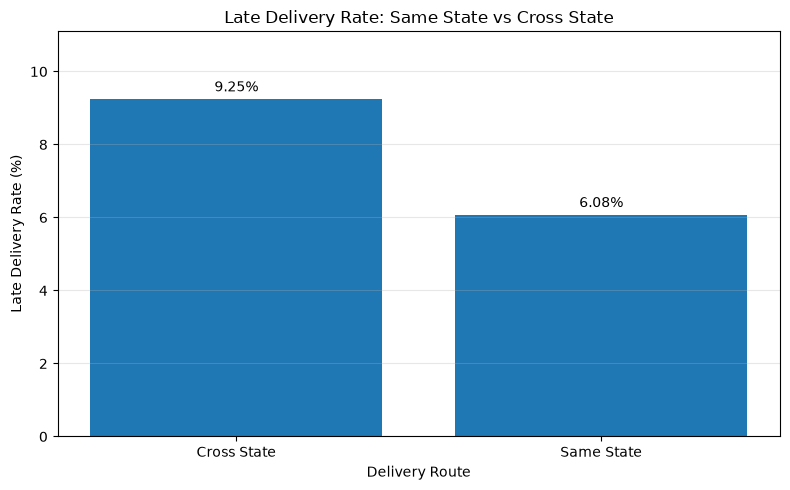

In [110]:
# Compare late delivery rates

plt.figure(figsize=(8, 5))

bars = plt.bar(
    route_performance["delivery_route"],
    route_performance["late_rate"]
)

plt.title("Late Delivery Rate: Same State vs Cross State")

plt.xlabel("Delivery Route")
plt.ylabel("Late Delivery Rate (%)")

plt.bar_label(bars, fmt="%.2f%%", padding=3)

plt.ylim(0, route_performance["late_rate"].max() * 1.2)

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [111]:
from scipy.stats import chi2_contingency

print("Statistical testing library ready!")

Statistical testing library ready!


In [112]:
# Create contingency table

contingency_table = pd.crosstab(
    route_analysis["delivery_route"],
    route_analysis["is_late"]
)

# Arrange rows and columns
contingency_table = contingency_table.reindex(
    index=["Same State", "Cross State"],
    columns=[False, True],
    fill_value=0
)

# Rename columns
contingency_table.columns = ["On Time", "Late"]

print("Delivery Route vs Delivery Outcome")
display(contingency_table)

Delivery Route vs Delivery Outcome


,On Time,Late
delivery_route,,
Same State,32472,2103
Cross State,56172,5723


In [113]:
# Perform Chi-Square Test

chi2, p_value, dof, expected = chi2_contingency(
    contingency_table,
    correction=False
)

print("Chi-Square Statistic:", round(chi2, 4))
print("Degrees of Freedom:", dof)
print("P-value:", p_value)

print("Minimum Expected Frequency:", expected.min())

Chi-Square Statistic: 297.8924
Degrees of Freedom: 1
P-value: 9.483194642070683e-67
Minimum Expected Frequency: 2804.850730797139


In [114]:
# Interpret the hypothesis test

alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("There is a statistically significant association.")
else:
    print("Fail to reject H0")
    print("There is insufficient evidence of an association.")

Reject H0
There is a statistically significant association.


In [115]:
from scipy.stats.contingency import association

# Calculate Cramer's V
cramers_v = association(
    contingency_table.to_numpy(),
    method="cramer",
    correction=False
)

print("Cramer's V:", round(cramers_v, 4))

Cramer's V: 0.0556


In [116]:
# Get exact rates from the original order counts

rates = (
    route_performance
    .set_index("delivery_route")
    ["late_orders"]
    / route_performance
    .set_index("delivery_route")
    ["total_orders"]
)

cross_rate = rates["Cross State"]
same_rate = rates["Same State"]

# Calculate difference in percentage points
rate_difference = (cross_rate - same_rate) * 100

# Calculate risk ratio
risk_ratio = cross_rate / same_rate

print("Difference:", round(rate_difference, 2),
      "percentage points")

print("Risk ratio:", round(risk_ratio, 2))

Difference: 3.16 percentage points
Risk ratio: 1.52


In [117]:
# Summarize statistical findings

print("STATISTICAL ANALYSIS SUMMARY")
print("----------------------------")

print("Test: Chi-Square Test of Independence")
print("Chi-Square Statistic:", round(chi2, 4))
print("Degrees of Freedom:", dof)
print("P-value:", p_value)
print("Cramer's V:", round(cramers_v, 4))
print("Risk Ratio:", round(risk_ratio, 2))
print("Difference:", round(rate_difference, 2),
      "percentage points")

if p_value < 0.05:
    print("Conclusion: Statistically significant association")
else:
    print("Conclusion: No statistically significant association")

STATISTICAL ANALYSIS SUMMARY
----------------------------
Test: Chi-Square Test of Independence
Chi-Square Statistic: 297.8924
Degrees of Freedom: 1
P-value: 9.483194642070683e-67
Cramer's V: 0.0556
Risk Ratio: 1.52
Difference: 3.16 percentage points
Conclusion: Statistically significant association


In [118]:
import numpy as np
from scipy.stats import norm

# Get exact order counts
route_counts = route_performance.set_index("delivery_route")

n1 = route_counts.loc["Cross State", "total_orders"]
n2 = route_counts.loc["Same State", "total_orders"]

x1 = route_counts.loc["Cross State", "late_orders"]
x2 = route_counts.loc["Same State", "late_orders"]

# Calculate proportions
p1 = x1 / n1
p2 = x2 / n2

# Difference between proportions
difference = p1 - p2

# Standard error
standard_error = np.sqrt(
    (p1 * (1 - p1) / n1) +
    (p2 * (1 - p2) / n2)
)

# 95% confidence interval
z = norm.ppf(0.975)

lower_bound = difference - z * standard_error
upper_bound = difference + z * standard_error

print("95% CONFIDENCE INTERVAL")
print("-----------------------")

print("Difference:", round(difference * 100, 2),
      "percentage points")

print("Lower bound:", round(lower_bound * 100, 2), "%")

print("Upper bound:", round(upper_bound * 100, 2), "%")

95% CONFIDENCE INTERVAL
-----------------------
Difference: 3.16 percentage points
Lower bound: 2.82 %
Upper bound: 3.5 %


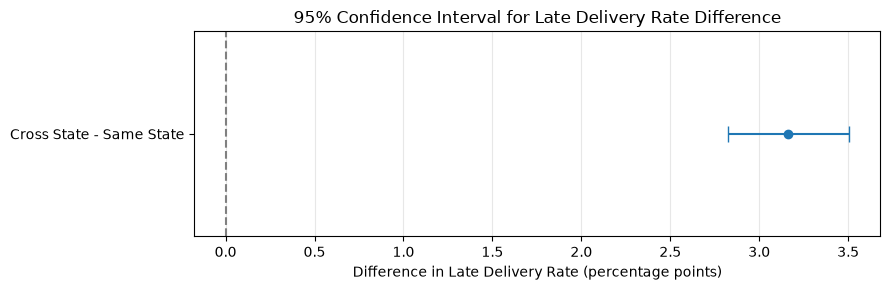

In [119]:
plt.figure(figsize=(9, 3))

plt.errorbar(
    difference * 100,
    0,
    xerr=[
        [difference * 100 - lower_bound * 100],
        [upper_bound * 100 - difference * 100]
    ],
    fmt="o",
    capsize=6
)

plt.axvline(0, linestyle="--", color="gray")

plt.yticks([0], ["Cross State - Same State"])

plt.xlabel("Difference in Late Delivery Rate (percentage points)")

plt.title("95% Confidence Interval for Late Delivery Rate Difference")

plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [120]:
# Display exact statistical results

print("FINAL STATISTICAL RESULTS")
print("-------------------------")

print("Cross-state late rate:", round(p1 * 100, 2), "%")
print("Same-state late rate:", round(p2 * 100, 2), "%")

print(
    "Difference:",
    round(difference * 100, 2),
    "percentage points"
)

print(
    "95% Confidence Interval: [",
    round(lower_bound * 100, 2),
    ",",
    round(upper_bound * 100, 2),
    "] percentage points"
)

print("P-value:", p_value)
print("Cramer's V:", round(cramers_v, 4))

FINAL STATISTICAL RESULTS
-------------------------
Cross-state late rate: 9.25 %
Same-state late rate: 6.08 %
Difference: 3.16 percentage points
95% Confidence Interval: [ 2.82 , 3.5 ] percentage points
P-value: 9.483194642070683e-67
Cramer's V: 0.0556


### Statistical Finding: Delivery Route and Late Delivery

**Business Question:** Are cross-state orders associated with higher late-delivery rates than same-state orders?

**Method:** Chi-Square Test of Independence, Cramér's V, and an approximate 95% confidence interval for the difference between two proportions.

**Key Findings:**
- Cross-state late-delivery rate: 9.25%.
- Same-state late-delivery rate: 6.08%.
- Difference: approximately 3.16 percentage points.
- Risk ratio: 1.52.
- Chi-Square statistic: 297.8924.
- P-value: approximately 9.48 × 10⁻⁶⁷.
- Cramér's V: 0.0556.

**Business Interpretation:**

Cross-state orders had a higher observed late-delivery rate than same-state orders. The association was statistically significant, although the overall association was weak according to Cramér's V.

**Recommendation:**

Investigate interstate delivery operations, particularly shipping routes and geographical areas with high delay rates. Consider customer location, seller characteristics, and seasonal patterns before making operational changes.

**Limitations:**

The analysis uses historical observational data. The confidence interval is unadjusted and assumes independent order outcomes. Other factors may explain part of the observed relationship, so the findings should not be interpreted as causal evidence.

In [121]:
# Prepare data for logistic regression

model_source = route_analysis.merge(
    customer_delivery[
        [
            "order_id",
            "customer_state",
            "order_purchase_timestamp"
        ]
    ],
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Save the dataset as a CSV file
model_source.to_csv(
    project_folder / "data" / "processed" /
    "delivery_model_data.csv",
    index=False
)

print("Regression dataset saved successfully!")

print("Dataset dimensions:", model_source.shape)

print(
    "Duplicate order IDs:",
    model_source["order_id"].duplicated().sum()
)

Regression dataset saved successfully!
Dataset dimensions: (96470, 8)
Duplicate order IDs: 0
